In [4]:
import re
import numpy as np
from gensim.models import Word2Vec
import matplotlib.pyplot as plt

file_path=r"F:\lp4\LP IV Updated Datasets\CBOW\document3.txt"

with open(file_path,"r",encoding="utf-8") as file:
    text=file.read()
print("Text loaded successfully",text)

Text loaded successfully The speed of transmission is an important point of difference between the two viruses. Influenza has a shorter median incubation period (the time from infection to appearance of symptoms) and a shorter serial interval (the time between successive cases) than COVID-19 virus. The serial interval for COVID-19 virus is estimated to be 5-6 days, while for influenza virus, the serial interval is 3 days. This means that influenza can spread faster than COVID-19. 

Further, transmission in the first 3-5 days of illness, or potentially pre-symptomatic transmission –transmission of the virus before the appearance of symptoms – is a major driver of transmission for influenza. In contrast, while we are learning that there are people who can shed COVID-19 virus 24-48 hours prior to symptom onset, at present, this does not appear to be a major driver of transmission. 

The reproductive number – the number of secondary infections generated from one infected individual – is un

In [8]:
text=text.lower()
text=re.sub(r'[^a-z\s.]','',text)
sentences=text.split('.')
tokenized_sentences=[]
for sentence in sentences:
    word=sentence.split()
    if len(word)>1:
        tokenized_sentences.append(word)
print(tokenized_sentences)        

[['the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses'], ['influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'the', 'time', 'from', 'infection', 'to', 'appearance', 'of', 'symptoms', 'and', 'a', 'shorter', 'serial', 'interval', 'the', 'time', 'between', 'successive', 'cases', 'than', 'covid', 'virus'], ['the', 'serial', 'interval', 'for', 'covid', 'virus', 'is', 'estimated', 'to', 'be', 'days', 'while', 'for', 'influenza', 'virus', 'the', 'serial', 'interval', 'is', 'days'], ['this', 'means', 'that', 'influenza', 'can', 'spread', 'faster', 'than', 'covid'], ['further', 'transmission', 'in', 'the', 'first', 'days', 'of', 'illness', 'or', 'potentially', 'presymptomatic', 'transmission', 'transmission', 'of', 'the', 'virus', 'before', 'the', 'appearance', 'of', 'symptoms', 'is', 'a', 'major', 'driver', 'of', 'transmission', 'for', 'influenza'], ['in', 'contrast', 'while', 'we', 'are', 'learning', 

In [10]:
model=Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=2,
    min_count=1,
    workers=4,
    sg=0,
    epochs=100
)

In [14]:
#wv=word vector

word=input("Enter a word:").lower()
if word in model.wv:
    print("Word:",word)
    print("Word embedding")
    print(model.wv[word])
    
    print("\nSimilar words:")
    similar_words=model.wv.most_similar(word,topn=5)
    
    #w represents a similar word.
    #score represents its cosine similarity score.
    for w,score in similar_words:
        print(w,score)
else:
    print("Word not found")

Enter a word: speed


Word: speed
Word embedding
[-1.03887904e-03  1.05488589e-02 -5.40708285e-03  8.38425010e-03
 -2.78602331e-03 -1.58017054e-02  1.00623723e-02  7.09298812e-03
 -1.05008641e-02 -1.35107925e-02 -6.15787599e-03 -2.22327784e-02
  5.17057441e-03 -2.91513465e-03  5.79762924e-03 -3.87957250e-03
 -5.91819361e-03 -1.24454452e-02  3.03551601e-03 -2.04856023e-02
  1.24572804e-02  7.69084692e-03  7.95927737e-03  5.74405817e-03
  8.24134564e-04 -6.04900764e-03 -8.50657560e-03  4.68109734e-03
 -4.52396041e-03 -2.41221767e-03  8.15064926e-03 -2.13987078e-03
  1.02349659e-02 -5.88730560e-04 -7.38126272e-03  3.95745179e-03
  1.50294146e-02 -6.82421261e-03  7.63146905e-04 -3.04148532e-03
  2.82078842e-03 -9.09903273e-03 -4.33349815e-05  1.92048633e-03
  1.00332443e-02  1.20894029e-03 -6.82418561e-03 -5.81848295e-03
  1.54256579e-02  5.55960136e-03  8.64937808e-03 -6.49038237e-04
  1.14708394e-02 -1.14708617e-02 -9.64279752e-03  2.61392328e-03
  2.78290128e-03 -3.98021238e-03 -1.08295372e-02 -1.41920126e-0

In [17]:

words=model.wv.index_to_key
if len(words)>=2:
    word1=input("Enter first word").lower()
    word2=input("Enter second word").lower()

    if word1 in model.wv and word2 in model.wv:
         similarity=model.wv.similarity(word1,word2)
         print("Similarity between", word1, "and", word2)
         print("Similarity Score:", similarity)

    else:
        print("One or both words not found in vocabulary!")

        

Enter first word virus
Enter second word symptom


Similarity between virus and symptom
Similarity Score: 0.90161455


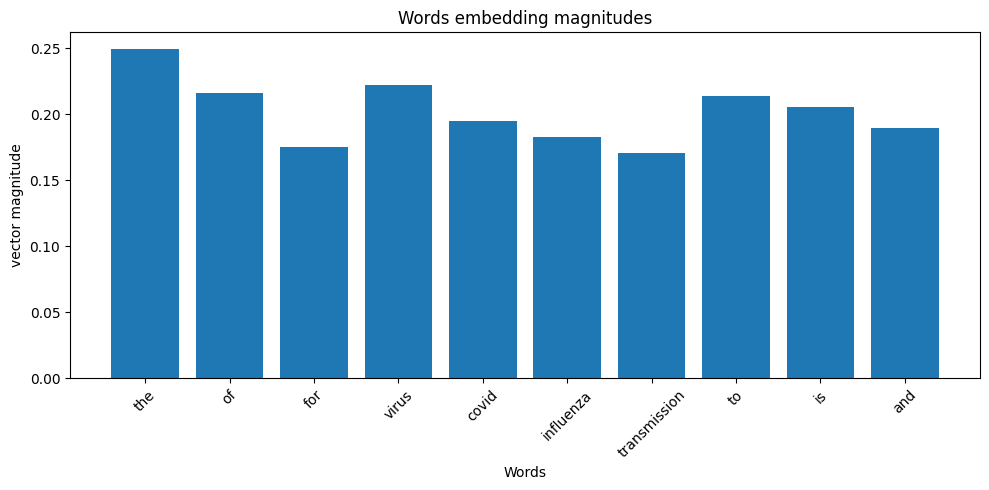

In [23]:
words=model.wv.index_to_key[:10]
vector=np.array([model.wv[w] for w in words])
plt.figure(figsize=(10,5))
plt.bar(words,np.linalg.norm(vector,axis=1))
plt.title("Words embedding magnitudes")
plt.xlabel("Words")
plt.ylabel("vector magnitude")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [21]:
model.save("cbow_model.model")

print("CBOW Model Saved Successfully!")

CBOW Model Saved Successfully!
